In [1]:
import pandas as pd

df = pd.read_csv("../data/jobs.csv", usecols=["title", "description"])
df = df.dropna().drop_duplicates()
df["title"] = df["title"].str.strip().str.lower()

print(df.shape)
df.head()

(110898, 2)


,title,description
0,marketing coordinator,Job descriptionA leading real estate firm in N...
1,mental health therapist/counselor,"At Aspen Therapy and Wellness , we are committ..."
2,assitant restaurant manager,The National Exemplar is accepting application...
3,senior elder law / trusts and estates associat...,Senior Associate Attorney - Elder Law / Trusts...
4,service technician,Looking for HVAC service tech with experience ...


In [2]:
rules = {
    "Healthcare": r"nurse|\brn\b|\blpn\b|\bcna\b|medical|physician|dental|dentist|pharmac|therapist|clinical|caregiver|health|veterinar|hygienist|surgeon|paramedic|phlebotom",
    "Technology": r"software|developer|data scientist|data engineer|data analyst|devops|cloud|cyber|network|programmer|database|machine learning|\bit\b|web ",
    "Education": r"teacher|instructor|professor|tutor|teaching|principal|school|faculty",
    "Finance & Accounting": r"accountant|accounting|finance|financial|auditor|bookkeep|payroll|\btax\b|controller|banker|banking|loan|underwriter|\bcpa\b",
    "Sales & Marketing": r"sales|account executive|account manager|business development|marketing|brand|social media|\bseo\b|advertis",
    "Customer Service & Admin": r"customer service|customer support|call center|client service|administrative|receptionist|secretary|clerk|data entry|\boffice\b|executive assistant|front desk",
    "Retail & Hospitality": r"store manager|cashier|retail|restaurant|server|cook|chef|bartender|barista|hotel|housekeep|kitchen|waiter|waitress|hospitality|\bhost\b|hostess",
    "Trades & Logistics": r"driver|warehouse|mechanic|electrician|plumber|hvac|maintenance|welder|forklift|delivery|operator|construction|installer|logistics|technician|carpenter|painter|laborer",
    "Engineering": r"engineer|engineering",
    "Management & Operations": r"manager|director|supervisor|operations|program",
}

df["category"] = "Other"
for category, pattern in rules.items():
    still_other = df["category"] == "Other"
    matches = df["title"].str.contains(pattern, regex=True)
    df.loc[still_other & matches, "category"] = category

print(df["category"].value_counts())

category
Other                       33530
Healthcare                  13640
Management & Operations     13462
Trades & Logistics          10738
Sales & Marketing           10314
Technology                   7708
Engineering                  6357
Finance & Accounting         6121
Customer Service & Admin     4186
Retail & Hospitality         2988
Education                    1854
Name: count, dtype: int64


In [3]:
for category in df["category"].unique():
    examples = df[df["category"] == category]["title"].head(4).tolist()
    print(category, "->", examples)

Sales & Marketing -> ['marketing coordinator', 'senior product marketing manager', 'salesperson', 'marketing & office coordinator']
Healthcare -> ['mental health therapist/counselor', 'respiratory therapist', 'physician assistant', 'registered nurse']
Retail & Hospitality -> ['assitant restaurant manager', 'workflow coordinator hospitality - mon - fri 8am-5pm', 'bench store manager', 'line cook - mercantile dining & provision - den airport']
Other -> ['senior elder law / trusts and estates associate attorney', 'economic development and planning intern', 'producer', 'worship leader']
Trades & Logistics -> ['service technician', 'general laborer', 'service / construction technician', 'hvac technician']
Engineering -> ['building engineer', 'structural engineer', 'full stack engineer', 'validation engineer, labware lims']
Customer Service & Admin -> ['inside customer service associate', 'administrative coordinator', 'customer service / reservationist', 'administrative assistant']
Finance &

In [4]:
rules = {
    "Healthcare": r"nurse|\brn\b|\blpn\b|\bcna\b|medical|physician|dental|dentist|pharmac|therapist|clinical|caregiver|health|veterinar|hygienist|surgeon|paramedic|phlebotom",
    "Technology": r"software|developer|data scientist|data engineer|data analyst|devops|cloud|cyber|network|programmer|database|machine learning|\bit\b|web |full.?stack|front.?end|back.?end|systems?\s(?:engineer|administrator|analyst)|qa\s(?:engineer|analyst|tester)",
    "Education": r"teacher|instructor|professor|tutor|teaching|faculty|school",
    "Legal": r"attorney|lawyer|paralegal|legal|law clerk|\bcounsel\b",
    "Finance & Accounting": r"accountant|accounting|finance|financial|auditor|bookkeep|payroll|\btax\b|controller|banker|banking|loan|underwriter|\bcpa\b",
    "Sales & Marketing": r"sales|account executive|account manager|business development|marketing|brand|social media|\bseo\b|advertis",
    "Customer Service & Admin": r"customer service|customer support|call center|client service|administrative|receptionist|secretary|clerk|data entry|\boffice\b|executive assistant|front desk",
    "Retail & Hospitality": r"store manager|cashier|retail|restaurant|server|cook|chef|bartender|barista|hotel|housekeep|kitchen|waiter|waitress|hospitality|\bhost\b|hostess",
    "Trades & Logistics": r"driver|warehouse|mechanic|electrician|plumber|hvac|maintenance|welder|forklift|delivery|operator|construction|installer|logistics|technician|carpenter|painter|laborer",
    "Engineering": r"engineer|engineering",
    "Management & Operations": r"manager|director|supervisor|operations|program",
}

df["category"] = "Other"
for category, pattern in rules.items():
    still_other = df["category"] == "Other"
    matches = df["title"].str.contains(pattern, regex=True)
    df.loc[still_other & matches, "category"] = category

print(df["category"].value_counts())

category
Other                       32052
Healthcare                  13640
Management & Operations     13472
Trades & Logistics          10735
Sales & Marketing           10316
Technology                   8779
Finance & Accounting         6093
Engineering                  5947
Customer Service & Admin     4078
Retail & Hospitality         2978
Legal                        1483
Education                    1325
Name: count, dtype: int64


In [5]:
from sklearn.model_selection import train_test_split

data = df[df["category"] != "Other"].copy()
print("Rows after removing Other:", len(data))

X_train, X_test, y_train, y_test = train_test_split(
    data["description"], data["category"],
    test_size=0.2, random_state=42, stratify=data["category"]
)
print("Train:", len(X_train), "Test:", len(X_test))

Rows after removing Other: 78846
Train: 63076 Test: 15770


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=20000,
    ngram_range=(1, 2),
    min_df=5,
)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print(X_train_vec.shape)
print(X_test_vec.shape)

(63076, 20000)
(15770, 20000)


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_vec, y_train)

pred_lr = model_lr.predict(X_test_vec)
print("Logistic Regression accuracy:", round(accuracy_score(y_test, pred_lr), 3))

Logistic Regression accuracy: 0.843


In [8]:
from sklearn.metrics import classification_report

print(classification_report(y_test, pred_lr))

                          precision    recall  f1-score   support

Customer Service & Admin       0.81      0.71      0.76       816
               Education       0.92      0.87      0.89       265
             Engineering       0.80      0.73      0.76      1189
    Finance & Accounting       0.90      0.87      0.89      1219
              Healthcare       0.91      0.92      0.92      2728
                   Legal       0.95      0.93      0.94       297
 Management & Operations       0.74      0.79      0.76      2694
    Retail & Hospitality       0.84      0.78      0.81       596
       Sales & Marketing       0.86      0.90      0.88      2063
              Technology       0.83      0.84      0.83      1756
      Trades & Logistics       0.87      0.86      0.86      2147

                accuracy                           0.84     15770
               macro avg       0.86      0.84      0.85     15770
            weighted avg       0.84      0.84      0.84     15770



In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_vec, y_train)

pred_lr = model_lr.predict(X_test_vec)
print("Logistic Regression accuracy:", round(accuracy_score(y_test, pred_lr), 3))
print()
print(classification_report(y_test, pred_lr))

Logistic Regression accuracy: 0.843

                          precision    recall  f1-score   support

Customer Service & Admin       0.81      0.71      0.76       816
               Education       0.92      0.87      0.89       265
             Engineering       0.80      0.73      0.76      1189
    Finance & Accounting       0.90      0.87      0.89      1219
              Healthcare       0.91      0.92      0.92      2728
                   Legal       0.95      0.93      0.94       297
 Management & Operations       0.74      0.79      0.76      2694
    Retail & Hospitality       0.84      0.78      0.81       596
       Sales & Marketing       0.86      0.90      0.88      2063
              Technology       0.83      0.84      0.83      1756
      Trades & Logistics       0.87      0.86      0.86      2147

                accuracy                           0.84     15770
               macro avg       0.86      0.84      0.85     15770
            weighted avg       0.84  

In [10]:
import time
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB

results = {"Logistic Regression": accuracy_score(y_test, pred_lr)}

start = time.time()
model_svm = LinearSVC()
model_svm.fit(X_train_vec, y_train)
pred_svm = model_svm.predict(X_test_vec)
results["Linear SVM"] = accuracy_score(y_test, pred_svm)
print("Linear SVM done in", round(time.time() - start), "seconds")

start = time.time()
model_nb = ComplementNB()
model_nb.fit(X_train_vec, y_train)
pred_nb = model_nb.predict(X_test_vec)
results["Naive Bayes"] = accuracy_score(y_test, pred_nb)
print("Naive Bayes done in", round(time.time() - start), "seconds")

print()
for name, acc in sorted(results.items(), key=lambda x: -x[1]):
    print(f"{name}: {acc:.3f}")

Linear SVM done in 65 seconds
Naive Bayes done in 1 seconds

Linear SVM: 0.857
Logistic Regression: 0.843
Naive Bayes: 0.744


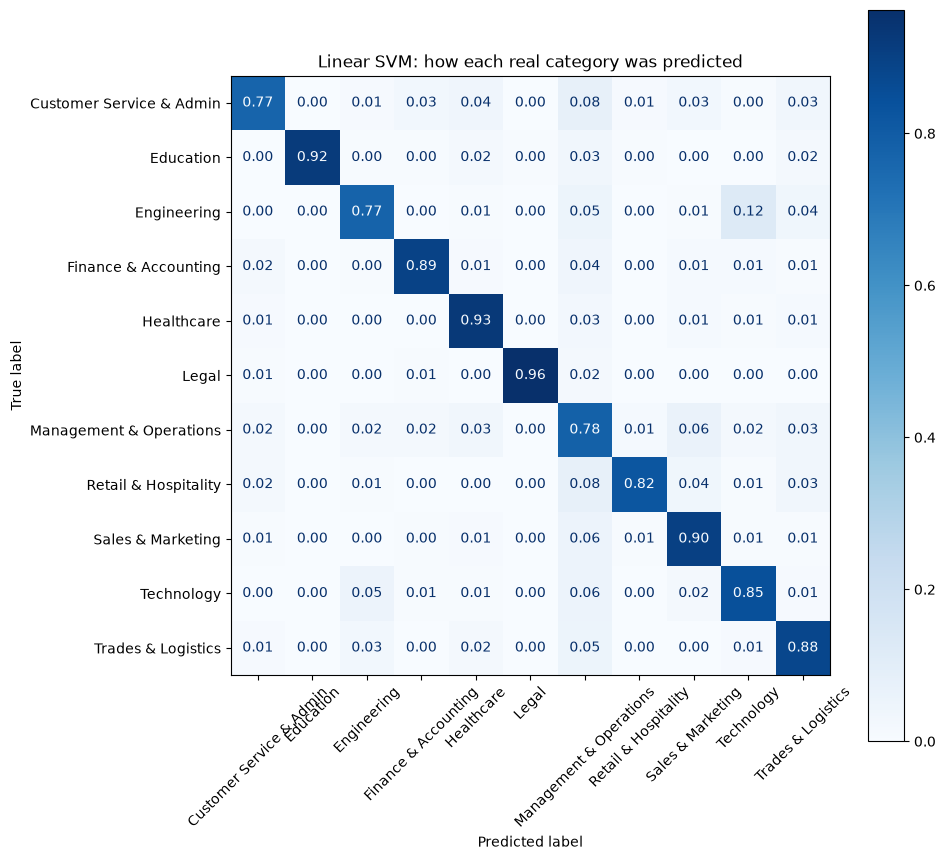

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_svm, normalize="true", xticks_rotation=45,
    values_format=".2f", cmap="Blues", ax=ax
)
plt.title("Linear SVM: how each real category was predicted")
plt.tight_layout()
plt.show()

In [12]:
from collections import Counter

mask = (y_test.values != pred_svm)
errors = Counter(zip(y_test.values[mask], pred_svm[mask]))

for (real, guess), n in errors.most_common(8):
    print(f"{real}  ->  predicted as {guess}: {n} times")

Management & Operations  ->  predicted as Sales & Marketing: 164 times
Engineering  ->  predicted as Technology: 148 times
Sales & Marketing  ->  predicted as Management & Operations: 115 times
Trades & Logistics  ->  predicted as Management & Operations: 109 times
Technology  ->  predicted as Management & Operations: 97 times
Technology  ->  predicted as Engineering: 95 times
Management & Operations  ->  predicted as Healthcare: 90 times
Management & Operations  ->  predicted as Trades & Logistics: 87 times


In [13]:
def predict_category(text):
    vec = vectorizer.transform([text])
    return model_svm.predict(vec)[0]

examples = [
    "We are hiring a registered nurse to provide patient care in our hospital ward and administer medication.",
    "Looking for a Python developer to build REST APIs and work with AWS and SQL databases.",
    "Seeking an experienced attorney to handle contracts and litigation for corporate clients.",
    "Sales representative needed to meet monthly revenue targets and grow client accounts.",
    "Forklift operator needed to load trucks and manage warehouse inventory.",
]

for text in examples:
    print(predict_category(text), "<-", text[:60])

Healthcare <- We are hiring a registered nurse to provide patient care in 
Technology <- Looking for a Python developer to build REST APIs and work w
Legal <- Seeking an experienced attorney to handle contracts and liti
Sales & Marketing <- Sales representative needed to meet monthly revenue targets 
Trades & Logistics <- Forklift operator needed to load trucks and manage warehouse


## Stage 2 findings: classifying job descriptions with classical machine learning

**Goal:** predict a job's category from its description text alone.

**Labels:** the dataset has no category column, so I created labels from the job titles using keyword rules (for example, a title containing "nurse" becomes Healthcare). This gave 11 categories plus "Other". I dropped "Other" (32,052 postings), which left **78,846 postings**.

| Category | Postings |
|---|---|
| Healthcare | 13,640 |
| Management & Operations | 13,472 |
| Trades & Logistics | 10,735 |
| Sales & Marketing | 10,316 |
| Technology | 8,779 |
| Finance & Accounting | 6,093 |
| Engineering | 5,947 |
| Customer Service & Admin | 4,078 |
| Retail & Hospitality | 2,978 |
| Legal | 1,483 |
| Education | 1,325 |

**Method**

- Split the data 80/20 (stratified): **63,076 training** and **15,770 test** descriptions.
- Converted text to numbers with **TF-IDF** (20,000 features, single words and two-word phrases, English stop words removed). The model sees only the description, never the title.
- Trained and compared three models on the same split.

**Results (accuracy on the 15,770 unseen test descriptions)**

| Model | Accuracy |
|---|---|
| **Linear SVM** | **0.857** |
| Logistic Regression | 0.843 |
| Naive Bayes | 0.744 |

- **Linear SVM** was the best model, though Logistic Regression was close. Naive Bayes trained in about 1 second but was roughly 11 points less accurate.
- For comparison, always guessing the largest category (Healthcare) would be right only about 17% of the time.
- Logistic Regression was strongest on **Legal** (f1 0.94), **Healthcare** (0.92), **Education** (0.89), and **Finance & Accounting** (0.89). It was weakest on **Customer Service & Admin**, **Engineering**, and **Management & Operations** (f1 0.76 each).

**Where the model makes mistakes (Linear SVM)**

- Errors are concentrated in neighboring categories: Engineering and Technology are mixed up in both directions (148 and 95 times), and so are Management & Operations and Sales & Marketing (164 and 115 times).
- **Management & Operations** acts as a catch-all, since "manager" can apply to any industry. It appears in five of the eight most common error pairs.
- Some of these mistakes may be errors in my keyword labels instead of the model. For example, a "practice manager" posting about patient care is arguably Healthcare.

**Sanity check:** I wrote five new job descriptions (nurse, Python developer, attorney, sales representative, forklift operator), and the model classified all five correctly.

**Limitations**

- The labels come from keyword rules on titles, so the accuracy measures how well the model reproduces those rules, not true human-labelled job types.
- Categories overlap in real life, which caps how accurate any model can be here.

**Next step:** Stage 3 will rebuild this classifier as a neural network in PyTorch and compare it with these results.